# 4. Exotic options

Three contracts for which the Black-Scholes formula is not enough. Each one is priced by simulation and validated against an independent method.

| Contract | Feature | Validation |
|---|---|---|
| Asian | payoff on the average price | geometric-average closed form |
| Barrier | cancelled or activated when a level is touched | closed form and PDE |
| American | can be exercised at any time | binomial tree |

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pricer` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricer import VanillaOption, black_scholes, monte_carlo, binomial, finite_difference, exotics
from pricer.greeks import bump_greeks
from pricer.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT

use_style()
pd.options.display.float_format = "{:.4f}".format

# Reference contract used throughout: an at-the-money one-year option.
call = VanillaOption(spot=100, strike=100, maturity=1.0, rate=0.05, vol=0.2, option_type="call")
put = call.with_(option_type="put")

## 4.1 Asian options

The payoff is $\max(\bar S - K, 0)$ where $\bar S$ is the **arithmetic** average of the price at $n$ dates. A sum of lognormals is not lognormal, so there is no closed form.

The **geometric** average, however, *is* lognormal and has a closed form. The two averages are almost perfectly correlated, which makes the geometric option an ideal control variate.

In [2]:
n_fixings, n = 50, 100_000
plain = exotics.asian_price(call, n_fixings, n, seed=1, control_variate=False)
controlled = exotics.asian_price(call, n_fixings, n, seed=1, control_variate=True)

pd.DataFrame([
    {"Quantity": "Geometric Asian, closed form", "Price": exotics.geometric_asian_price(call, n_fixings), "Std error": np.nan},
    {"Quantity": "Arithmetic Asian, plain Monte Carlo", "Price": plain.price, "Std error": plain.std_error},
    {"Quantity": "Arithmetic Asian, with control variate", "Price": controlled.price, "Std error": controlled.std_error},
    {"Quantity": "European call (for comparison)", "Price": black_scholes.price(call), "Std error": np.nan},
]).set_index("Quantity")

,Price,Std error
Quantity,,
"Geometric Asian, closed form",5.6411,NaN
"Arithmetic Asian, plain Monte Carlo",5.8995,0.0257
"Arithmetic Asian, with control variate",5.8583,0.0007
European call (for comparison),10.4506,NaN


In [3]:
print(f"Variance divided by {(plain.std_error / controlled.std_error) ** 2:,.0f}: "
      f"{n:,} paths with the control variate are worth "
      f"{n * (plain.std_error / controlled.std_error) ** 2:,.0f} plain paths.")

Variance divided by 1,302: 100,000 paths with the control variate are worth 130,209,989 plain paths.


Averaging reduces the volatility of the quantity the option is written on, so an Asian call is cheaper than the European call. The effect of the number of averaging dates:

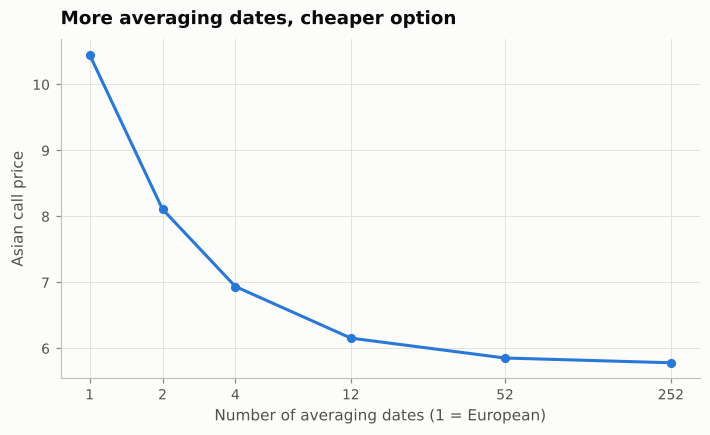

In [4]:
fixings = [1, 2, 4, 12, 52, 252]
prices = [exotics.asian_price(call, k, 100_000, seed=1).price for k in fixings]
fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.plot(fixings, prices, marker="o", color=BLUE)
ax.set_xscale("log"); ax.set_xticks(fixings, [str(k) for k in fixings]); ax.minorticks_off()
ax.set_xlabel("Number of averaging dates (1 = European)"); ax.set_ylabel("Asian call price")
ax.set_title("More averaging dates, cheaper option");

## 4.2 Barrier options

A **down-and-out** call is a call that is cancelled if the price ever touches a barrier $H < S_0$. Knock-in and knock-out versions add up to the vanilla option.

A simulation only sees the path at a finite number of dates, so it misses the crossings that happen in between and overprices knock-outs. The fix used here weights each step by the exact probability that a Brownian bridge between its end points stays above the barrier:

$$\mathbb{P}(\text{no hit}) = 1 - \exp\!\left(-\frac{2\,\ln(S_i/H)\,\ln(S_{i+1}/H)}{\sigma^2\,\Delta t}\right).$$

In [5]:
barrier = 90.0
rows = []
for barrier_type, level in [("down-and-out", 90.0), ("down-and-in", 90.0), ("up-and-out", 130.0), ("up-and-in", 130.0)]:
    mc = exotics.barrier_price_mc(call, level, barrier_type, n_paths=200_000, seed=3)
    rows.append({"Type": barrier_type, "Barrier": level,
                 "Closed form": exotics.barrier_price_analytic(call, level, barrier_type),
                 "Finite differences": exotics.barrier_price_fd(call, level, barrier_type),
                 "Monte Carlo": mc.price, "MC std error": mc.std_error})
table = pd.DataFrame(rows).set_index("Type")
print(f"Vanilla call: {black_scholes.price(call):.4f} (= in + out for each barrier)")
table

Vanilla call: 10.4506 (= in + out for each barrier)


,Barrier,Closed form,Finite differences,Monte Carlo,MC std error
Type,,,,,
down-and-out,90.0000,8.6655,8.6653,8.6828,0.0325
down-and-in,90.0000,1.7851,1.7847,1.7779,0.0125
up-and-out,130.0000,3.3329,3.3328,3.3265,0.0133
up-and-in,130.0000,7.1177,7.1172,7.1343,0.0335


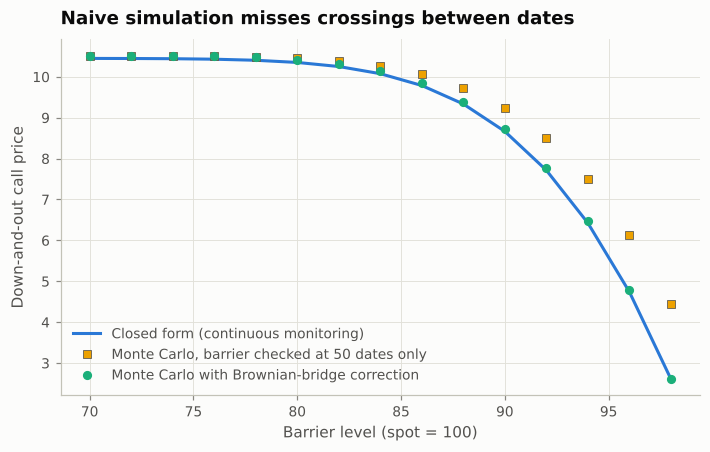

In [6]:
barriers = np.linspace(70, 98, 15)
analytic = [exotics.barrier_price_analytic(call, b, "down-and-out") for b in barriers]
bridge = [exotics.barrier_price_mc(call, b, "down-and-out", 50, 100_000, seed=2).price for b in barriers]
naive = [exotics.barrier_price_mc(call, b, "down-and-out", 50, 100_000, seed=2, brownian_bridge=False).price
         for b in barriers]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(barriers, analytic, color=BLUE, label="Closed form (continuous monitoring)")
ax.plot(barriers, naive, linestyle="none", marker="s", color=YELLOW, markeredgecolor=INK_SOFT, markeredgewidth=0.5,
        label="Monte Carlo, barrier checked at 50 dates only")
ax.plot(barriers, bridge, linestyle="none", marker="o", color=AQUA, label="Monte Carlo with Brownian-bridge correction")
ax.set_xlabel("Barrier level (spot = 100)"); ax.set_ylabel("Down-and-out call price")
ax.set_title("Naive simulation misses crossings between dates"); ax.legend(loc="lower left");

The bias of the naive simulation shrinks only like $1/\sqrt{\text{number of dates}}$, while the corrected estimator is unbiased with any number of dates:

In [7]:
exact = exotics.barrier_price_analytic(call, 90.0, "down-and-out")
rows = []
for n_steps in [10, 50, 250]:
    naive_mc = exotics.barrier_price_mc(call, 90.0, "down-and-out", n_steps, 200_000, seed=5, brownian_bridge=False)
    bridge_mc = exotics.barrier_price_mc(call, 90.0, "down-and-out", n_steps, 200_000, seed=5)
    rows.append({"Monitoring dates": n_steps, "Naive bias": naive_mc.price - exact,
                 "Corrected bias": bridge_mc.price - exact, "MC std error": bridge_mc.std_error})
pd.DataFrame(rows).set_index("Monitoring dates")

,Naive bias,Corrected bias,MC std error
Monitoring dates,,,
10,1.0085,0.0472,0.0320
50,0.4585,-0.0626,0.0323
250,0.2528,0.0070,0.0326


## 4.3 American options by simulation: Longstaff-Schwartz

Monte Carlo moves forward in time, but the exercise decision requires the value of *continuing*, which depends on the future. The Longstaff-Schwartz algorithm estimates this continuation value by **regression**: going backwards from expiry, the discounted future cash flows of the in-the-money paths are regressed on a polynomial of the current price. A path is exercised when its payoff exceeds the fitted continuation value.

In [8]:
rows = []
for strike in [90, 100, 110]:
    option = put.with_(strike=strike)
    lsm = exotics.american_price_lsm(option, n_steps=50, n_paths=200_000, seed=6)
    rows.append({"Strike": strike, "Longstaff-Schwartz": lsm.price, "Std error": lsm.std_error,
                 "Binomial tree": binomial.price(option, 2000, american=True),
                 "European (exact)": black_scholes.price(option)})
pd.DataFrame(rows).set_index("Strike")

,Longstaff-Schwartz,Std error,Binomial tree,European (exact)
Strike,,,,
90,2.4646,0.0089,2.4726,2.3101
100,6.0695,0.0096,6.0900,5.5735
110,11.9501,0.0112,11.9732,10.6753


The simulated prices sit slightly below the tree: exercise is only allowed at 50 dates and the regression gives a slightly sub-optimal exercise rule, so the estimator is biased low. More exercise dates reduce the gap:

In [9]:
reference = binomial.price(put, 2000, american=True)
rows = []
for n_steps in [5, 10, 25, 50, 100]:
    lsm = exotics.american_price_lsm(put, n_steps=n_steps, n_paths=200_000, seed=6)
    rows.append({"Exercise dates": n_steps, "Price": lsm.price, "Gap to tree": lsm.price - reference,
                 "Std error": lsm.std_error})
pd.DataFrame(rows).set_index("Exercise dates")

,Price,Gap to tree,Std error
Exercise dates,,,
5,6.0053,-0.0847,0.0108
10,6.0449,-0.0451,0.0101
25,6.0702,-0.0198,0.0097
50,6.0695,-0.0205,0.0096
100,6.0820,-0.0080,0.0096


## Summary

* **Asian**: the geometric control variate reduces the variance by three orders of magnitude.
* **Barrier**: closed form, PDE and simulation agree once the Brownian-bridge correction is applied.
* **American**: Longstaff-Schwartz matches the binomial tree within its statistical and discretisation error, and unlike the tree it extends to many underlyings.